# AdversarialQA Dataset Exploration

This notebook performs exploratory data analysis of the AdversarialQA dataset.

The analysis covers four configurations:
- dbert
- dbidaf
- adversarialQA
- droberta

Each configuration is examined across training, validation and test splits.

The objective is to understand dataset structure, quality, answerability,
question characteristics and answer distributions before preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Dataset Path Identification and File Inspection

In [2]:
PROJECT_ROOT = Path.cwd().parents[1]

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "adversarial_qa"

configurations = ["dbert", "dbidaf", "adversarialQA", "droberta"]
splits = ["train", "validation", "test"]

print("Project root:", PROJECT_ROOT)
print("Dataset folder exists:", DATA_PATH.exists())

for config in configurations:
    print(f"\n{config.upper()}")

    for split in splits:
        file_path = DATA_PATH / config / split / "0000.parquet"

        print(
            split,
            "| Exists:", file_path.exists(),
            "| Path:", file_path
        )

Project root: /Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-
Dataset folder exists: True

DBERT
train | Exists: True | Path: /Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-/data/raw/adversarial_qa/dbert/train/0000.parquet
validation | Exists: True | Path: /Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-/data/raw/adversarial_qa/dbert/validation/0000.parquet
test | Exists: True | Path: /Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-/data/raw/adversarial_qa/dbert/test/0000.parquet

DBIDAF
train | Exists: True | Path: /Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-/data/raw/adversarial_qa/dbidaf/train/0000.parquet
validation | Exists: True | Path: /Users/deepika/Desktop/Domain-Adaptive-and-Robustness-Aware-Question-Answering-/data/raw/adversarial_qa/dbidaf/validation/0000.parquet
test | Exists: True | Path: /Users/deepika/Desktop/Do

## Load the datasets and inspect their structure.

In [3]:
import pandas as pd

dataframes = {}

for config in configurations:
    for split in splits:
        file_path = DATA_PATH / config / split / "0000.parquet"

        df = pd.read_parquet(file_path)
        dataframes[(config, split)] = df

        print(f"\n{'='*50}")
        print(f"Configuration: {config.upper()} | Split: {split}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print("\nData types:")
        print(df.dtypes)
        print("\nFirst sample:")
        display(df.head(1))


Configuration: DBERT | Split: train
Shape: (10000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']

Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object

First sample:


,id,title,context,question,answers,metadata
0,dab017ed8a1c27c6afa2d8618abc3a477a4edffc,Empiricism,"A generation later, the Irish Anglican bishop,...",what concept is mentioned last?,"{'text': ['subjective idealism'], 'answer_star...","{'split': 'train', 'model_in_the_loop': 'BERT-..."



Configuration: DBERT | Split: validation
Shape: (1000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']

Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object

First sample:


,id,title,context,question,answers,metadata
0,21a3561031f2e909338196601f5c1ac2e08905b6,Teacher,A 2000 study found that 42% of UK teachers exp...,What is teaching not considered due to stress?,"{'text': ['average profession'], 'answer_start...","{'split': 'validation', 'model_in_the_loop': '..."



Configuration: DBERT | Split: test
Shape: (1000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']

Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object

First sample:


,id,title,context,question,answers,metadata
0,4b6027a3eceaa4a26d4e2a8d74646e583114d928,Computational_complexity_theory,Many types of Turing machines are used to defi...,What kind of Turing machines are equally power...,"{'text': [], 'answer_start': []}","{'split': 'test', 'model_in_the_loop': 'BERT-L..."


... (14 outputs left out)


Configuration: DROBERTA | Split: validation
Shape: (1000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']

Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object

First sample:


,id,title,context,question,answers,metadata
0,0622161680ff6c97fa14a25b01a4bf3bc289d72f,Amazon_rainforest,"Between 1991 and 2000, the total area of fores...",What consumer product are the rain forests cle...,"{'text': ['soybeans'], 'answer_start': [386]}","{'split': 'validation', 'model_in_the_loop': '..."



Configuration: DROBERTA | Split: test
Shape: (1000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']

Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object

First sample:


,id,title,context,question,answers,metadata
0,906fbd5561058d810da6e7ab17d041672cf334cb,Victoria_and_Albert_Museum,In the immediate post-war years there was litt...,Who made what was used to make the facade?,"{'text': [], 'answer_start': []}","{'split': 'test', 'model_in_the_loop': 'RoBERT..."


In [4]:
for config in configurations:
    df = dataframes[(config, "train")]

    print(f"\n{config.upper()}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Data types:")
    print(df.dtypes)


DBERT
Shape: (10000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']
Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object

DBIDAF
Shape: (10000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']
Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object

ADVERSARIALQA
Shape: (30000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']
Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object

DROBERTA
Shape: (10000, 6)
Columns: ['id', 'title', 'context', 'question', 'answers', 'metadata']
Data types:
id             str
title          str
context        str
question       str
answers     object
metadata    object
dtype: object


 Inspect nested fields

In [5]:
sample = dataframes[("dbert", "train")].iloc[0]

print("Answers structure:")
print(sample["answers"])

print("\nMetadata structure:")
print(sample["metadata"])

Answers structure:
{'text': array(['subjective idealism'], dtype=object), 'answer_start': array([742], dtype=int32)}

Metadata structure:
{'split': 'train', 'model_in_the_loop': 'BERT-Large'}


## Check missing values and duplicates

In [6]:
for config in configurations:
    print(f"\n{'='*40}")
    print(config.upper())

    for split in splits:
        df = dataframes[(config, split)]

        print(f"\n{split.upper()}")
        print("Missing values:")
        print(df.isnull().sum().to_dict())
        print("Duplicate IDs:", df["id"].duplicated().sum())
        print("Duplicate rows:", df.duplicated(subset=["id"]).sum())


DBERT

TRAIN
Missing values:
{'id': 0, 'title': 0, 'context': 0, 'question': 0, 'answers': 0, 'metadata': 0}
Duplicate IDs: 0
Duplicate rows: 0

VALIDATION
Missing values:
{'id': 0, 'title': 0, 'context': 0, 'question': 0, 'answers': 0, 'metadata': 0}
Duplicate IDs: 0
Duplicate rows: 0

TEST
Missing values:
{'id': 0, 'title': 0, 'context': 0, 'question': 0, 'answers': 0, 'metadata': 0}
Duplicate IDs: 0
Duplicate rows: 0

DBIDAF

TRAIN
Missing values:
{'id': 0, 'title': 0, 'context': 0, 'question': 0, 'answers': 0, 'metadata': 0}
Duplicate IDs: 0
Duplicate rows: 0

VALIDATION
Missing values:
{'id': 0, 'title': 0, 'context': 0, 'question': 0, 'answers': 0, 'metadata': 0}
Duplicate IDs: 0
Duplicate rows: 0

TEST
Missing values:
{'id': 0, 'title': 0, 'context': 0, 'question': 0, 'answers': 0, 'metadata': 0}
Duplicate IDs: 0
Duplicate rows: 0

ADVERSARIALQA

TRAIN
Missing values:
{'id': 0, 'title': 0, 'context': 0, 'question': 0, 'answers': 0, 'metadata': 0}
Duplicate IDs: 35
Duplicate row

## Answerability distribution


In [7]:
for config in configurations:
    print(f"\n{'='*45}")
    print(config.upper())

    for split in splits:
        df = dataframes[(config, split)]

        answerable = df["answers"].apply(
            lambda x: len(x["text"]) > 0
        )

        print(f"\n{split.upper()}")
        print("Total:", len(df))
        print("Answerable:", answerable.sum())
        print("Unanswerable:", (~answerable).sum())
        print("Answerable %:", round(answerable.mean() * 100, 2))
        print("Unanswerable %:", round((~answerable).mean() * 100, 2))


DBERT

TRAIN
Total: 10000
Answerable: 10000
Unanswerable: 0
Answerable %: 100.0
Unanswerable %: 0.0

VALIDATION
Total: 1000
Answerable: 1000
Unanswerable: 0
Answerable %: 100.0
Unanswerable %: 0.0

TEST
Total: 1000
Answerable: 0
Unanswerable: 1000
Answerable %: 0.0
Unanswerable %: 100.0

DBIDAF

TRAIN
Total: 10000
Answerable: 10000
Unanswerable: 0
Answerable %: 100.0
Unanswerable %: 0.0

VALIDATION
Total: 1000
Answerable: 1000
Unanswerable: 0
Answerable %: 100.0
Unanswerable %: 0.0

TEST
Total: 1000
Answerable: 0
Unanswerable: 1000
Answerable %: 0.0
Unanswerable %: 100.0

ADVERSARIALQA

TRAIN
Total: 30000
Answerable: 30000
Unanswerable: 0
Answerable %: 100.0
Unanswerable %: 0.0

VALIDATION
Total: 3000
Answerable: 3000
Unanswerable: 0
Answerable %: 100.0
Unanswerable %: 0.0

TEST
Total: 3000
Answerable: 0
Unanswerable: 3000
Answerable %: 0.0
Unanswerable %: 100.0

DROBERTA

TRAIN
Total: 10000
Answerable: 10000
Unanswerable: 0
Answerable %: 100.0
Unanswerable %: 0.0

VALIDATION
Total: 1

In [8]:
rows = []

for config in configurations:
    for split in splits:
        df = dataframes[(config, split)]

        answerable = df["answers"].apply(
            lambda x: len(x["text"]) > 0
        )

        rows.append({
            "Configuration": config,
            "Split": split,
            "Total": len(df),
            "Non-empty answers": answerable.sum(),
            "Empty answers": (~answerable).sum()
        })

answerability_df = pd.DataFrame(rows)
display(answerability_df)

,Configuration,Split,Total,Non-empty answers,Empty answers
0,dbert,train,10000,10000,0
1,dbert,validation,1000,1000,0
2,dbert,test,1000,0,1000
3,dbidaf,train,10000,10000,0
4,dbidaf,validation,1000,1000,0
5,dbidaf,test,1000,0,1000
6,adversarialQA,train,30000,30000,0
7,adversarialQA,validation,3000,3000,0
8,adversarialQA,test,3000,0,3000
9,droberta,train,10000,10000,0


## Question, context and answer length analysis

In [9]:
for config in configurations:
    print(f"\n{'='*45}")
    print(config.upper())

    for split in ["train", "validation"]:
        df = dataframes[(config, split)]

        question_lengths = df["question"].apply(
            lambda x: len(x.split())
        )

        context_lengths = df["context"].apply(
            lambda x: len(x.split())
        )

        answer_lengths = df["answers"].apply(
            lambda x: [
                len(answer.split()) for answer in x["text"]
            ]
        ).explode().dropna()

        print(f"\n{split.upper()}")

        print("Question words - Mean:", round(question_lengths.mean(), 2),
              "| Median:", question_lengths.median())

        print("Context words - Mean:", round(context_lengths.mean(), 2),
              "| Median:", context_lengths.median())

        print("Answer words - Mean:", round(answer_lengths.mean(), 2),
              "| Median:", answer_lengths.median())


DBERT

TRAIN
Question words - Mean: 9.52 | Median: 9.0
Context words - Mean: 118.26 | Median: 108.0
Answer words - Mean: 3.78 | Median: 2.0

VALIDATION
Question words - Mean: 9.77 | Median: 9.0
Context words - Mean: 114.62 | Median: 106.0
Answer words - Mean: 2.96 | Median: 2.0

DBIDAF

TRAIN
Question words - Mean: 9.44 | Median: 9.0
Context words - Mean: 118.01 | Median: 108.0
Answer words - Mean: 3.8 | Median: 2.0

VALIDATION
Question words - Mean: 9.76 | Median: 9.0
Context words - Mean: 115.27 | Median: 108.0
Answer words - Mean: 2.94 | Median: 2.0

ADVERSARIALQA

TRAIN
Question words - Mean: 9.55 | Median: 9.0
Context words - Mean: 117.36 | Median: 108.0
Answer words - Mean: 3.97 | Median: 2.0

VALIDATION
Question words - Mean: 9.84 | Median: 9.0
Context words - Mean: 114.83 | Median: 108.0
Answer words - Mean: 3.03 | Median: 2.0

DROBERTA

TRAIN
Question words - Mean: 9.68 | Median: 9.0
Context words - Mean: 115.81 | Median: 106.0
Answer words - Mean: 4.34 | Median: 2.0

VALIDAT

In [10]:
for config in configurations:
    print(f"\n{config.upper()}")

    for split in ["train", "validation"]:
        df = dataframes[(config, split)]

        q = df["question"].str.split().str.len()
        c = df["context"].str.split().str.len()

        a = df["answers"].apply(
            lambda x: [len(t.split()) for t in x["text"]]
        ).explode().dropna()

        print(
            f"{split}: "
            f"Q={q.mean():.2f}/{q.median():.0f}, "
            f"C={c.mean():.2f}/{c.median():.0f}, "
            f"A={a.mean():.2f}/{a.median():.0f}"
        )


DBERT
train: Q=9.52/9, C=118.26/108, A=3.78/2
validation: Q=9.77/9, C=114.62/106, A=2.96/2

DBIDAF
train: Q=9.44/9, C=118.01/108, A=3.80/2
validation: Q=9.76/9, C=115.27/108, A=2.94/2

ADVERSARIALQA
train: Q=9.55/9, C=117.36/108, A=3.97/2
validation: Q=9.84/9, C=114.83/108, A=3.03/2

DROBERTA
train: Q=9.68/9, C=115.81/106, A=4.34/2
validation: Q=9.99/9, C=114.61/109, A=3.17/1


## Visualise text-length comparisons

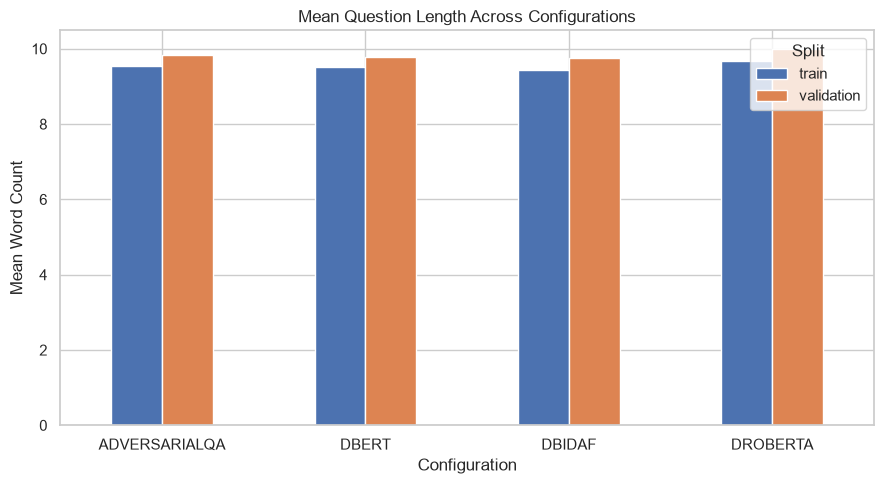

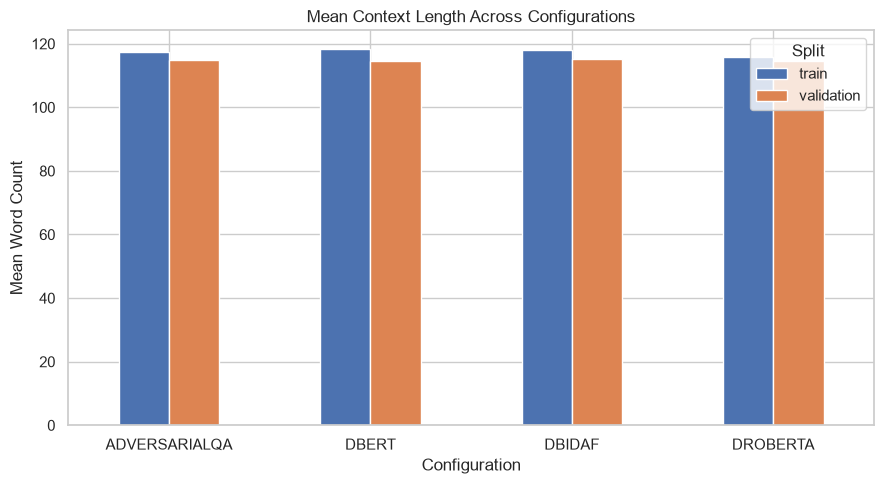

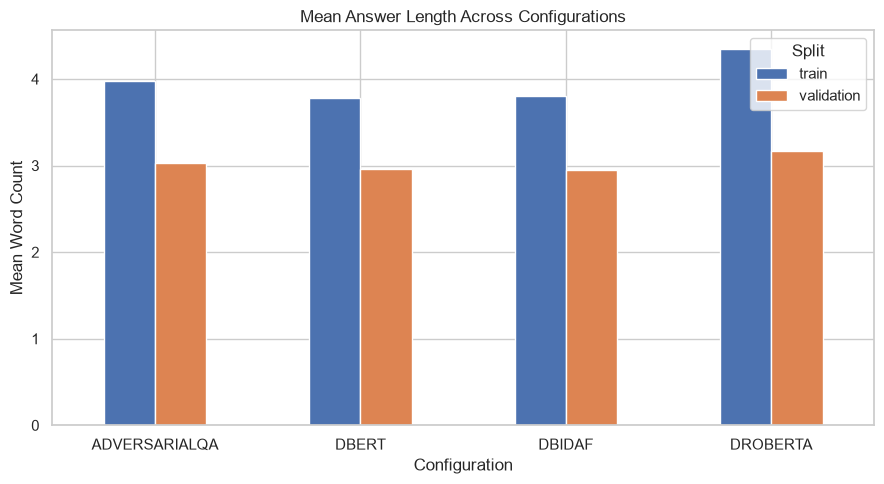

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

metrics = {
    "Question Length": "question",
    "Context Length": "context",
    "Answer Length": "answers"
}

results = []

for config in configurations:
    for split in ["train", "validation"]:
        df = dataframes[(config, split)]

        q_mean = df["question"].str.split().str.len().mean()
        c_mean = df["context"].str.split().str.len().mean()

        a_lengths = df["answers"].apply(
            lambda x: [len(t.split()) for t in x["text"]]
        ).explode().dropna()

        results.append({
            "Configuration": config.upper(),
            "Split": split,
            "Question Length": q_mean,
            "Context Length": c_mean,
            "Answer Length": a_lengths.mean()
        })

length_df = pd.DataFrame(results)

for metric in metrics:
    pivot = length_df.pivot(
        index="Configuration",
        columns="Split",
        values=metric
    )

    ax = pivot.plot(kind="bar", figsize=(9, 5))
    ax.set_title(f"Mean {metric} Across Configurations")
    ax.set_ylabel("Mean Word Count")
    ax.set_xlabel("Configuration")
    ax.legend(title="Split")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

## Inspect sample questions and answers

In [13]:
for config in configurations:
    df = dataframes[(config, "train")]

    print(f"\n{'='*55}")
    print(config.upper())

    for i in range(2):
        row = df.iloc[i]

        print(f"\nExample {i+1}")
        print("Question:", row["question"])
        print("Answer:", row["answers"]["text"])
        print("Context:", row["context"][:400], "...")


DBERT

Example 1
Question: what concept is mentioned last?
Answer: ['subjective idealism']
Context: A generation later, the Irish Anglican bishop, George Berkeley (1685–1753), determined that Locke's view immediately opened a door that would lead to eventual atheism. In response to Locke, he put forth in his Treatise Concerning the Principles of Human Knowledge (1710) an important challenge to empiricism in which things only exist either as a result of their being perceived, or by virtue of the  ...

Example 2
Question: what concept is mentioned first?
Answer: ['atheism']
Context: A generation later, the Irish Anglican bishop, George Berkeley (1685–1753), determined that Locke's view immediately opened a door that would lead to eventual atheism. In response to Locke, he put forth in his Treatise Concerning the Principles of Human Knowledge (1710) an important challenge to empiricism in which things only exist either as a result of their being perceived, or by virtue of the  ...

DBIDA

## Final sample check for DROberta

In [14]:
df = dataframes[("droberta", "train")]

for i in range(2):
    row = df.iloc[i]

    print(f"\nExample {i+1}")
    print("Question:", row["question"])
    print("Answer:", row["answers"]["text"])
    print("Context:", row["context"][:300], "...")


Example 1
Question: What jewelry like accessories did he wear?
Answer: ["Légion d'honneur star, medal and ribbon, and the Order of the Iron Crown decorations"]
Context: When he became First Consul and later Emperor, Napoleon eschewed his general's uniform and habitually wore the simple green colonel uniform (non-Hussar) of a colonel of the Chasseur à Cheval of the Imperial Guard, the regiment that often served as his personal escort, with a large bicorne. He also h ...

Example 2
Question: What accessory could have fallen from the night sky?
Answer: ["his Légion d'honneur star"]
Context: When he became First Consul and later Emperor, Napoleon eschewed his general's uniform and habitually wore the simple green colonel uniform (non-Hussar) of a colonel of the Chasseur à Cheval of the Imperial Guard, the regiment that often served as his personal escort, with a large bicorne. He also h ...


## Investigate the duplicate IDs

In [15]:
df = dataframes[("adversarialQA", "train")]

duplicates = df[df["id"].duplicated(keep=False)].sort_values("id")

print("Rows involved:", len(duplicates))
print("Unique duplicated IDs:", duplicates["id"].nunique())

display(
    duplicates[["id", "title", "question", "answers"]].head(15)
)

# Check whether the complete records are identical
import json

row_signatures = df.apply(
    lambda row: json.dumps(row.to_dict(), sort_keys=True, default=str),
    axis=1
)

print(
    "Exact duplicate records:",
    row_signatures.duplicated().sum()
)

Rows involved: 70
Unique duplicated IDs: 35


,id,title,question,answers
780,06f0fc11ac4afbd691e3318326f505c204f40bd4,Tennessee,What happened in the 57th year of the 18th cen...,{'text': ['Captain Raymond Demeré relinquished...
787,06f0fc11ac4afbd691e3318326f505c204f40bd4,Tennessee,What happened in the 57th year of the 18th cen...,{'text': ['Captain Raymond Demeré relinquished...
27314,17c4021092c54a222b3357ece608acbe63d932e3,Estonian_language,"What does the S in ""SVO"" stand for?","{'text': ['subject'], 'answer_start': [143]}"
27316,17c4021092c54a222b3357ece608acbe63d932e3,Estonian_language,"What does the S in ""SVO"" stand for?","{'text': ['subject'], 'answer_start': [143]}"
11073,202b2db2a023b1328bc31de7d52a5661ae4d9a98,Internet_service_provider,What is web hosting?,"{'text': ['Internet services'], 'answer_start'..."
11076,202b2db2a023b1328bc31de7d52a5661ae4d9a98,Internet_service_provider,What is web hosting?,"{'text': ['Internet services'], 'answer_start'..."
13674,36b1366067af52a5d96893a3f71b89b88b174c34,Sexual_orientation,What does the O stand for in SASO?,"{'text': ['Orientation'], 'answer_start': [30]}"
13684,36b1366067af52a5d96893a3f71b89b88b174c34,Sexual_orientation,What does the O stand for in SASO?,"{'text': ['Orientation'], 'answer_start': [30]}"
5891,37b2f1140a24eb1c750c75fced296c998a7619b3,Federalism,What was Russia a part of?,"{'text': ['Soviet Union'], 'answer_start': [237]}"
5894,37b2f1140a24eb1c750c75fced296c998a7619b3,Federalism,What was Russia a part of?,"{'text': ['the USSR'], 'answer_start': [145]}"


Exact duplicate records: 25


Identify the 10 records

In [17]:
import json

df = dataframes[("adversarialQA", "train")]

# Get all rows with repeated IDs
duplicate_ids = df[df["id"].duplicated(keep=False)].copy()

# Convert complete records into comparable strings
duplicate_ids["_signature"] = duplicate_ids.apply(
    lambda row: json.dumps(row.drop(labels="_signature", errors="ignore").to_dict(),
                           sort_keys=True, default=str),
    axis=1
)

# Count distinct records for each duplicated ID
id_summary = duplicate_ids.groupby("id")["_signature"].nunique()

# IDs associated with different records
different_ids = id_summary[id_summary > 1].index

different_records = duplicate_ids[
    duplicate_ids["id"].isin(different_ids)
]

print("Total duplicated IDs:", duplicate_ids["id"].nunique())
print("IDs with different records:", len(different_ids))
print("Rows involved:", len(different_records))

display(
    different_records[
        ["id", "title", "question", "answers"]
    ].sort_values("id")
)

Total duplicated IDs: 35
IDs with different records: 10
Rows involved: 20


,id,title,question,answers
780,06f0fc11ac4afbd691e3318326f505c204f40bd4,Tennessee,What happened in the 57th year of the 18th cen...,{'text': ['Captain Raymond Demeré relinquished...
787,06f0fc11ac4afbd691e3318326f505c204f40bd4,Tennessee,What happened in the 57th year of the 18th cen...,{'text': ['Captain Raymond Demeré relinquished...
5891,37b2f1140a24eb1c750c75fced296c998a7619b3,Federalism,What was Russia a part of?,"{'text': ['Soviet Union'], 'answer_start': [237]}"
5894,37b2f1140a24eb1c750c75fced296c998a7619b3,Federalism,What was Russia a part of?,"{'text': ['the USSR'], 'answer_start': [145]}"
18754,57c2c33b7d89ce702818e98d05d353dec4e4cd3e,IPod,What is Harman Kardon?,"{'text': ['manufacturers'], 'answer_start': [24]}"
18758,57c2c33b7d89ce702818e98d05d353dec4e4cd3e,IPod,What is Harman Kardon?,"{'text': ['independent stereo manufacturers'],..."
28376,6e223ba9d4b9a915cd805f5d9f1849361ac9b3e6,Southern_Europe,What was the Columbian Exchange comprised of?,{'text': ['resource inflows from the New World...
28377,6e223ba9d4b9a915cd805f5d9f1849361ac9b3e6,Southern_Europe,What was the Columbian Exchange comprised of?,"{'text': ['colonial empires'], 'answer_start':..."
20240,794e467afa80c99cbfdfcba7b5a3290ddcf9848e,Antenna_(radio),What may affect the choice of an antenna?,"{'text': ['antenna design'], 'answer_start': [..."
20244,794e467afa80c99cbfdfcba7b5a3290ddcf9848e,Antenna_(radio),What may affect the choice of an antenna?,"{'text': ['feedpoint impedance'], 'answer_star..."


Inspect all 10 cases

In [18]:
for uid in different_ids:
    group = different_records[different_records["id"] == uid]

    print("\n" + "=" * 60)
    print("ID:", uid)

    for _, row in group.iterrows():
        print("Question:", row["question"])
        print("Answer:", row["answers"]["text"])
        print("Answer start:", row["answers"]["answer_start"])


ID: 06f0fc11ac4afbd691e3318326f505c204f40bd4
Question: What happened in the 57th year of the 18th century?
Answer: ['Captain Raymond Demeré relinquished command']
Answer start: [366]
Question: What happened in the 57th year of the 18th century?
Answer: ['Captain Raymond Demeré relinquished command on August 14, 1757 to his brother']
Answer start: [366]

ID: 37b2f1140a24eb1c750c75fced296c998a7619b3
Question: What was Russia a part of?
Answer: ['Soviet Union']
Answer start: [237]
Question: What was Russia a part of?
Answer: ['the USSR']
Answer start: [145]

ID: 57c2c33b7d89ce702818e98d05d353dec4e4cd3e
Question: What is Harman Kardon?
Answer: ['manufacturers']
Answer start: [24]
Question: What is Harman Kardon?
Answer: ['independent stereo manufacturers']
Answer start: [5]

ID: 6e223ba9d4b9a915cd805f5d9f1849361ac9b3e6
Question: What was the Columbian Exchange comprised of?
Answer: ['resource inflows from the New World and the Industrial Revolution of Great Britain']
Answer start: [118]
Q

Validate answer offsets

In [19]:
validation_results = []

for _, row in different_records.iterrows():
    context = row["context"]
    answers = row["answers"]

    for answer, start in zip(
        answers["text"], answers["answer_start"]
    ):
        extracted = context[start:start + len(answer)]

        validation_results.append({
            "id": row["id"],
            "answer": answer,
            "answer_start": start,
            "extracted_text": extracted,
            "valid": extracted == answer
        })

offset_df = pd.DataFrame(validation_results)

print("Total answer annotations:", len(offset_df))
print("Valid offsets:", offset_df["valid"].sum())
print("Invalid offsets:", (~offset_df["valid"]).sum())

display(offset_df[offset_df["valid"] == False])

Total answer annotations: 20
Valid offsets: 20
Invalid offsets: 0


,id,answer,answer_start,extracted_text,valid


In [20]:
quality_rows = []

for config in configurations:
    for split in splits:
        df = dataframes[(config, split)]

        quality_rows.append({
            "Configuration": config,
            "Split": split,
            "Missing Values": int(df.isnull().sum().sum()),
            "Duplicate IDs": int(df["id"].duplicated().sum())
        })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)

,Configuration,Split,Missing Values,Duplicate IDs
0,dbert,train,0,0
1,dbert,validation,0,0
2,dbert,test,0,0
3,dbidaf,train,0,0
4,dbidaf,validation,0,0
5,dbidaf,test,0,0
6,adversarialQA,train,0,35
7,adversarialQA,validation,0,0
8,adversarialQA,test,0,0
9,droberta,train,0,0


## Final EDA Findings – AdversarialQA

### 1. Dataset Overview
- Four configurations were explored: DBERT, DBIDAF, AdversarialQA and DROberta.
- Each configuration contains training, validation and test splits.
- AdversarialQA contains 30,000 training examples, while the other configurations contain 10,000 each.

### 2. Data Quality
- No missing values were found across the 12 splits.
- Duplicate IDs were found only in the AdversarialQA training split (35).
- Further investigation identified 25 exact duplicate record occurrences and 10 IDs associated with differing records.
- All 20 answer annotations from the differing records passed character-offset validation.

### 3. Answerability
- All training and validation examples contain non-empty answer annotations.
- Test examples contain empty answer arrays. Their answerability cannot be determined from these files because ground-truth answers are unavailable.

### 4. Text-Length Analysis
- Question lengths are broadly similar across configurations.
- Context lengths are also comparable.
- DROberta has the highest mean answer length in training and validation.
- Median answer lengths are generally between one and two words.

### 5. Qualitative Observations
- The configurations contain different question formulations and answer types.
- Questions include factual retrieval, concept identification and detail-based questions.
- Some examples contain alternative answer annotations for the same question.

### 6. Limitations and Considerations
- Different configurations have different dataset sizes.
- Repeated IDs and differing answer annotations require careful handling during later data preparation.
- Test answer labels are unavailable in the inspected files.
- No preprocessing, tokenization or model training was performed during this exploration.

### Conclusion
The exploratory analysis established the structure, data quality, answerability patterns and text characteristics of the four AdversarialQA configurations. These findings will guide subsequent preprocessing and comparative model experiments.